# Elastic-net GLM: opening model with opening/closing predictions
Train a binomial GLM using `alpha` and `L1_wt`, then export simulator-compatible predictions. This follows `lr_open_close.ipynb`: train-only fitting for validation; optional train + validation fitting for final test predictions. Original Logit artifacts are kept separate.

Probability standard errors come from bootstrap refits of whole **training events**, including preprocessing. They describe parameter variability conditional on the chosen features and hyperparameters, not calibrated confidence intervals. Saved betting controls in `sim_results.ipynb` are reused; they have not been optimized for this GLM.

In [9]:
from pathlib import Path
import sys
project_root = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / 'src/ufc_betting').is_dir()), None)
if project_root is None:
    raise RuntimeError('Open this notebook from inside SportsBetting.')
for p in (project_root, project_root / 'src'):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

import joblib
import pandas as pd
from IPython.display import display
from sklearn.metrics import brier_score_loss, accuracy_score
from ufc_betting.config import settings
from ufc_betting.Models.LogisticRegression.train_test_builder import TrainTestBuilder
from ufc_betting.Models.LogisticRegression.glm_workflow import fit_glm_bundle, predict_glm_bundle
from ufc_betting.Models.LogisticRegression.visual_functions import plot_model_metrics
from ufc_betting.Models.Search.prediction_input import read_frozen_predictions

In [10]:
# Match the data and dates used by lr_open_close.ipynb.
INPUT_PATH = settings.all_feats_dir / 'entire_odds_stats_2026-10-11.csv'
VAL_START_DATE = pd.Timestamp('2024-05-11')
TEST_START_DATE = pd.Timestamp('2026-02-21')
ALPHA = 0.012388237415089284
L1_WT = 0.7516134248157892

N_BOOTSTRAP = 50  # Training-event refits for probability standard errors.
SEED = 42

REFIT_TRAIN_VAL = True    # Refit with frozen hyperparameters for final test exports
SHOW_PLOTS = True
# EDIT: prediction CSV folder that sim_results.ipynb will read.
results_dir = Path(r"C:/Users/jcmar/my_files/SportsBetting/Data/model_predictions/glm")
artifact_dir = settings.data_dir / 'glm_models'
plots_dir = settings.images_dir / 'plot_pngs' / 'glm'
for folder in (results_dir, artifact_dir, plots_dir):
    folder.mkdir(parents=True, exist_ok=True)
df_model = pd.read_csv(INPUT_PATH)

In [11]:
open_feats = ['proba_fair_open_diff', 'reach_diff', 'sub_att_pm_red', 'sub_att_pm_blue', 'td_attempted_pm_diff', 'td_defended_pm_diff', 'adjusted_td_diff', 'adjusted_control_diff', 'adjusted_sig_str_diff', 'sig_str_absorbed_pm_diff', 'kd_total_diff', 'sig_str_accuracy_pct_diff', 'sig_str_defense_pct_diff', 'win_pct_red', 'win_pct_blue', 'win_streak_diff', 'lose_streak_diff', 'elo_red', 'elo_blue', 'elo_pred', 'age_diff', 'opp_age_red', 'opp_age_blue']

builder = TrainTestBuilder(
    df=df_model, feats=open_feats, target_col='winner', date_col='date',
    odds_type='open', year=2010, month=2, day=26, retain_void_evaluation=True,
)
pkt = builder.prepare_train_test(
    val_start_date=VAL_START_DATE, test_start_date=TEST_START_DATE, scale=False,
)
display(pd.DataFrame([
    dict(split=split, rows=len(pkt[f'{split}_df']),
         first_date=pkt[f'{split}_df'].date.min(), last_date=pkt[f'{split}_df'].date.max())
    for split in ('train', 'val', 'test')
]))

Filtered: kept 4936 rows from 2010-02-26 onward.
PREPARE SHAPE: (4936, 53)
train: 3,994 rows (80.92%) | 2010-03-21 to 2024-05-04
val: 664 rows (13.45%) | 2024-05-11 to 2026-02-07
test: 278 rows (5.63%) | 2026-02-21 to 2026-10-03


,split,rows,first_date,last_date
0,train,3994,2010-03-21,2024-05-04
1,val,664,2024-05-11,2026-02-07
2,test,278,2026-02-21,2026-10-03


In [12]:
# Fit directly with the ALPHA and L1_WT values entered above.
params = dict(alpha=ALPHA, L1_wt=L1_WT)
train_bundle = fit_glm_bundle(
    pkt['X_train'], pkt['y_train'], pkt['train_df']['date'],
    **params, n_bootstrap=N_BOOTSTRAP, seed=SEED,
)
joblib.dump(train_bundle, artifact_dir / 'glm_open_train.joblib')
print('Fitted GLM with:', params)


Fitted GLM with: {'alpha': 0.012388237415089284, 'L1_wt': 0.7516134248157892}


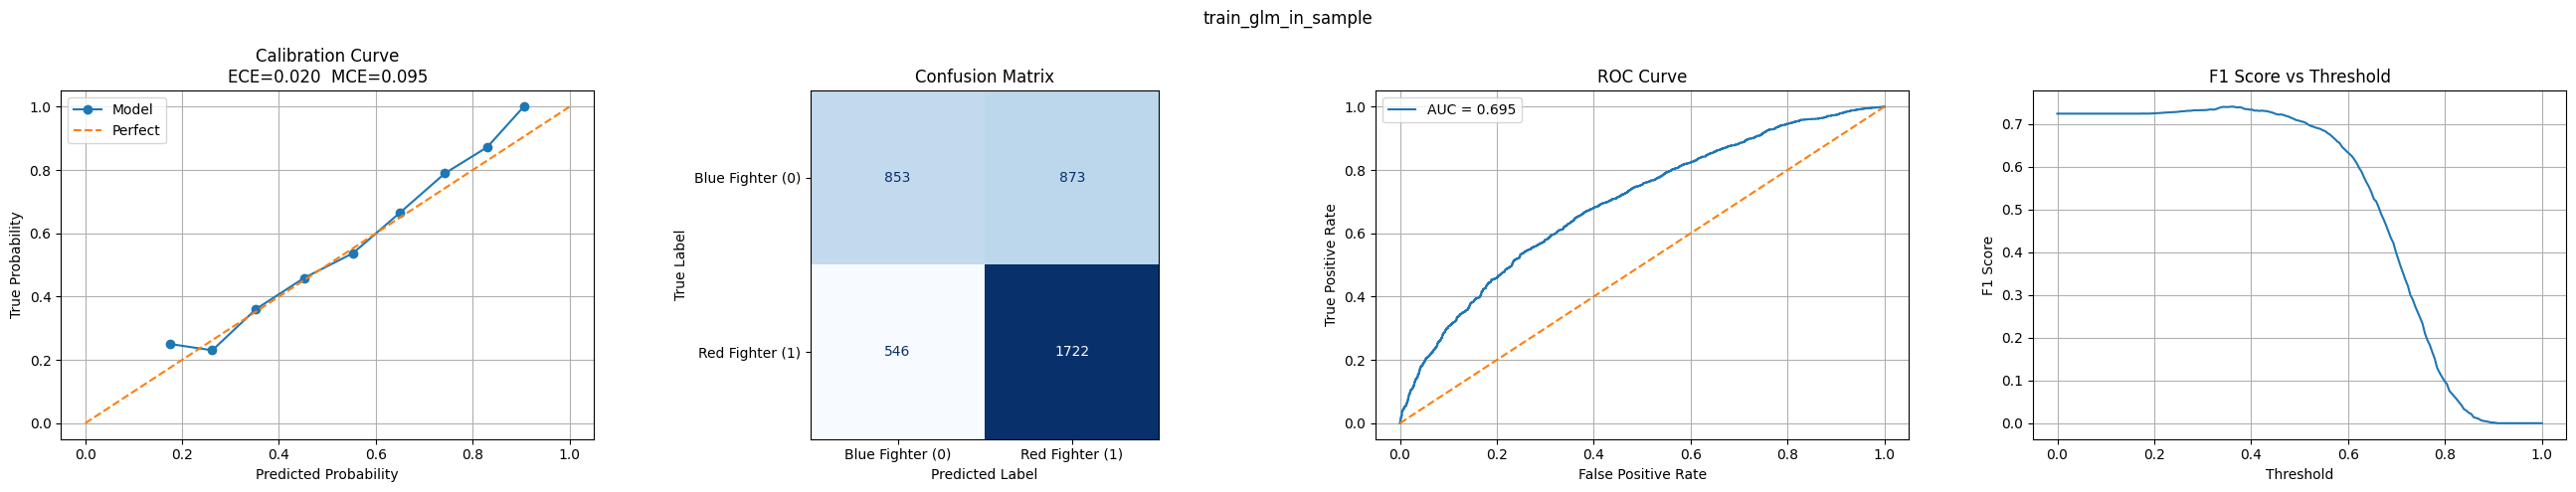

{'dataset': 'train_glm_in_sample',
 'rows': 3994,
 'brier': 0.21804121544011448,
 'accuracy': 0.6447170756134202}

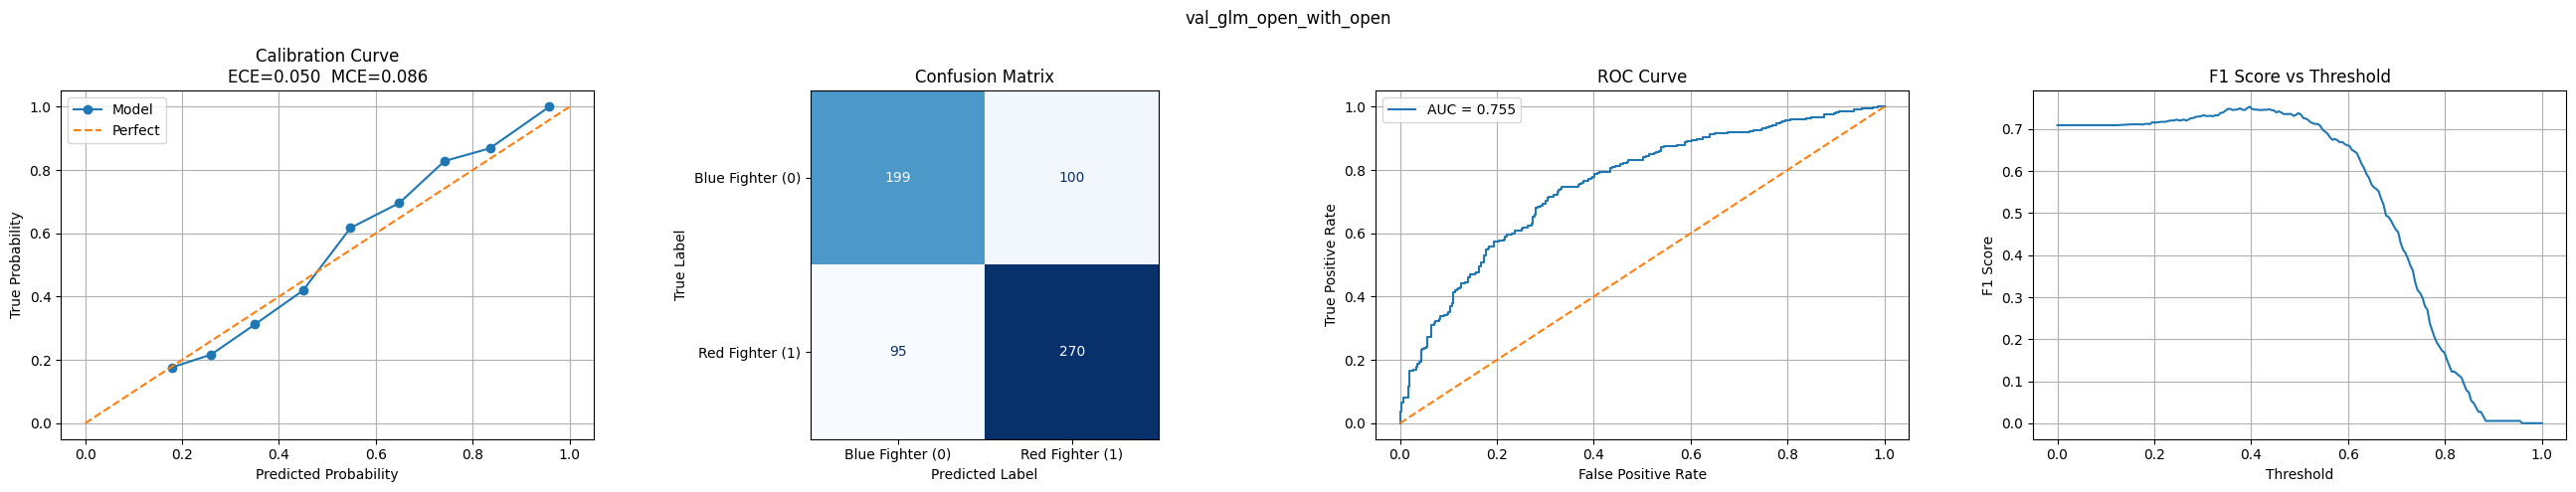

C:\Users\jcmar\my_files\SportsBetting\Data\model_predictions\glm\val_glm_open_with_open.csv


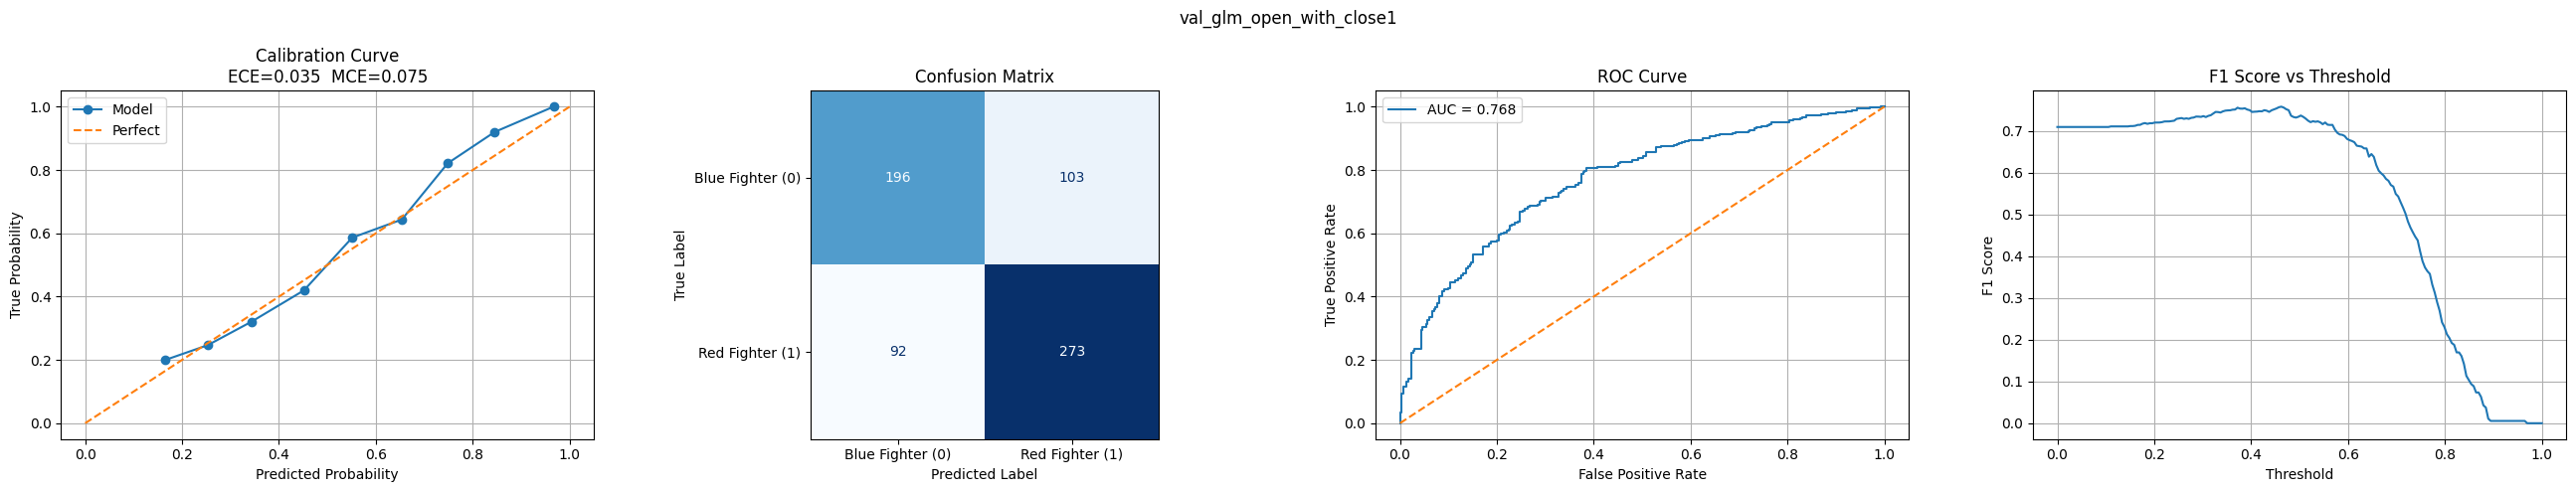

C:\Users\jcmar\my_files\SportsBetting\Data\model_predictions\glm\val_glm_open_with_close1.csv


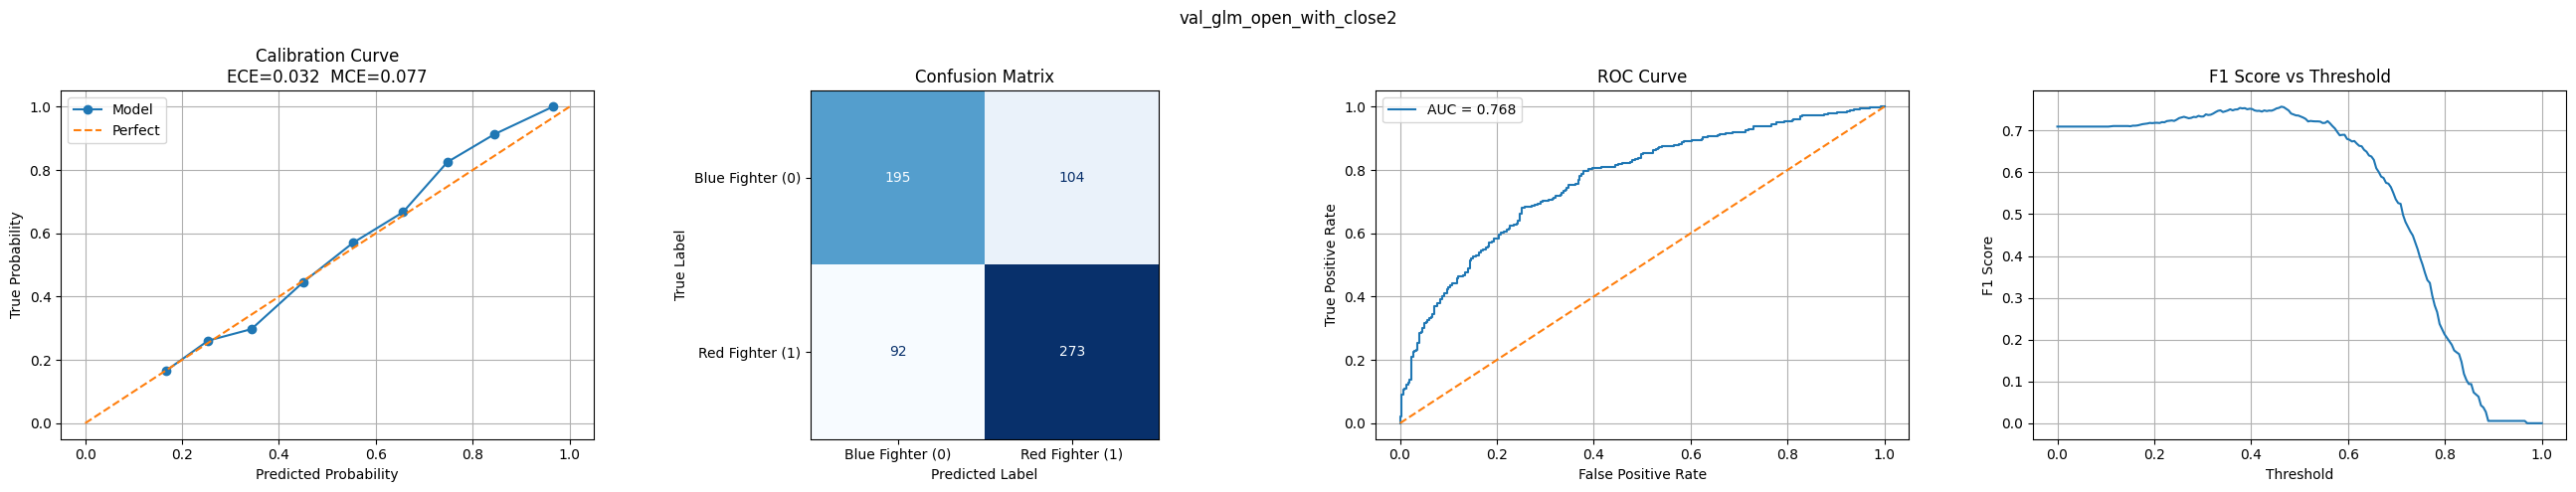

C:\Users\jcmar\my_files\SportsBetting\Data\model_predictions\glm\val_glm_open_with_close2.csv


,dataset,rows,brier,accuracy
0,val_glm_open_with_open,664,0.201664,0.706325
1,val_glm_open_with_close1,664,0.195792,0.706325
2,val_glm_open_with_close2,664,0.196089,0.704819


In [13]:
def report_predictions(rows, *, label):
    evaluated = rows.loc[rows['winner'].isin([0, 1])]
    metrics = dict(dataset=label, rows=len(evaluated),
                   brier=brier_score_loss(evaluated.winner, evaluated.proba_red),
                   accuracy=accuracy_score(evaluated.winner, evaluated.pred_winner))
    if SHOW_PLOTS and evaluated.winner.nunique() == 2:
        plot_model_metrics(evaluated.winner, evaluated.pred_winner, evaluated.proba_red,
                           suptitle=label, path=plots_dir / f'{label}.png')
    return metrics


def export_markets(rows, bundle, split, *, save_dir=None):
    save_dir = Path(save_dir) if save_dir is not None else results_dir
    save_dir.mkdir(parents=True, exist_ok=True)
    predictions, metrics = {}, []
    for market in ('open', 'close1', 'close2'):
        path = save_dir / f'{split}_glm_open_with_{market}.csv'
        predictions[market] = predict_glm_bundle(rows, bundle, odds_type=market, fp=path)
        read_frozen_predictions(path)  # Check the simulator's required prediction schema.
        metrics.append(report_predictions(predictions[market], label=f'{split}_glm_open_with_{market}'))
        print(path)
    display(pd.DataFrame(metrics))
    return predictions

# Training metrics are in-sample; validation remains held out.
train_predictions = predict_glm_bundle(pkt['train_df'], train_bundle)
display(report_predictions(train_predictions, label='train_glm_in_sample'))
val_predictions = export_markets(pkt['val_df'], train_bundle, 'val')

## Final test predictions
Optionally fit train + validation with the selected parameters held fixed. Test outcomes are used only for reporting. The validation CSVs above continue to come from the train-only model.

In [ ]:
if REFIT_TRAIN_VAL:
    X_fit = pd.concat([pkt['X_train'], pkt['X_val']], ignore_index=True)
    y_fit = pd.concat([pkt['y_train'], pkt['y_val']], ignore_index=True)
    dates_fit = pd.concat([pkt['train_df']['date'], pkt['val_df']['date']], ignore_index=True)
    fit_mask = y_fit.isin([0, 1])
    X_fit, y_fit, dates_fit = X_fit.loc[fit_mask], y_fit.loc[fit_mask], dates_fit.loc[fit_mask]
    test_bundle = fit_glm_bundle(X_fit, y_fit, dates_fit, **params,
                                n_bootstrap=N_BOOTSTRAP, seed=SEED)
else:
    test_bundle = train_bundle
joblib.dump(test_bundle, artifact_dir / 'glm_open_test.joblib')
test_predictions = export_markets(pkt['test_df'], test_bundle, 'test')

## Predict with a saved model
This cell demonstrates saved-model inference without fitting. Replace `inference_rows` with your own full feature rows, including the market odds columns. Use the train-only bundle for validation and the test bundle for dates after the test cutoff.

In [ ]:
saved_bundle = joblib.load(artifact_dir / 'glm_open_test.joblib')
inference_rows = pkt['test_df'].copy()
inference_results = predict_glm_bundle(inference_rows, saved_bundle, odds_type='close1')
display(inference_results[['date', 'fighter_red', 'fighter_blue', 'proba_red', 'prediction_se']].head())

## Open these exports in sim_results.ipynb
Run the following cell and copy its printed `prediction_options` into the configuration cell in `sim_results.ipynb`. The absolute template points all three markets, including bootstrap comparisons, to your chosen results folder. Set `split` to `val` or `test`.


In [ ]:
# Print the exact configuration for sim_results.ipynb.
simulation_template = str(results_dir.resolve() / '{split}_glm_{model_type}_with_{odds_type}.csv')
print('prediction_options = dict(')
print('    split="val",  # Change to "test" for test predictions.')
print('    model_type="open",')
print(f'    prediction_template={simulation_template!r},')
print(')')
